# 🎵 Spotify Track Popularity Prediction: A Complete Machine Learning Guide

## 📌 Project Overview & Problem Statement
Can acoustic data tell us how popular a song will become? In the music streaming era, Spotify hosts over 100 million tracks. Understanding what makes a track catch fire is a multi-billion dollar question for artists, record labels, and algorithmic recommendation systems.

In this project, we formulate this challenge as a **classical supervised regression task**:
- **Target Variable ($y$):** `popularity` — a continuous score from **0 to 100** assigned by Spotify's internal streaming algorithm based on total stream counts and recent listening velocity.
- **Input Features ($X$):** Acoustic audio properties extracted from the raw audio waveform (such as *danceability*, *energy*, *tempo*, *loudness*, *acousticness*, and *valence*) along with metadata like *genre*, *key*, *mode*, and *explicitness*.
- **Machine Learning Scope:** Classical statistical and ensemble machine learning algorithms (**no deep learning / neural networks**).

---

## 📖 Pedagogical Guide: How to Read This Notebook
This notebook is crafted specifically for **students and aspiring data scientists**. For every code block, you will find:
1. **Plain-English Markdown explanation before the code:** Detailing *what* we are executing, *why* we chose this method, and *what patterns to look for* in the resulting output.
2. **Clean, documented code:** Following industry-standard practices, avoiding deprecations, and eliminating data leakage.
3. **What We Learned summary:** A conceptual wrap-up consolidating the key machine learning takeaways after each major section.

---

## 📑 Table of Contents
1. [Project Overview & Problem Statement](#-project-overview--problem-statement)
2. [Imports, Environment & Reproducibility Setup](#2-imports-environment--reproducibility-setup)
3. [Automated Data Ingestion & Initial Inspection](#3-automated-data-ingestion--initial-inspection)
4. [Data Cleaning & Rigorous Leakage Prevention](#4-data-cleaning--rigorous-leakage-prevention)
5. [Exploratory Data Analysis (EDA) & Acoustic Insights](#5-exploratory-data-analysis-eda--acoustic-insights)
6. [Feature Engineering & Preprocessing Pipelines](#6-feature-engineering--preprocessing-pipelines)
7. [Leakage-Free Train/Test Split (GroupShuffleSplit)](#7-leakage-free-traintest-split-groupshufflesplit)
8. [Model Comparison & 5-Fold Group Cross-Validation](#8-model-comparison--5-fold-group-cross-validation)
9. [Hyperparameter Optimization (RandomizedSearchCV)](#9-hyperparameter-optimization-randomizedsearchcv)
10. [Final Evaluation on Held-Out Test Set](#10-final-evaluation-on-held-out-test-set)
11. [Feature Importance: Built-In vs. Permutation Importance](#11-feature-importance-built-in-vs-permutation-importance)
12. [In-Depth Error Analysis & Failure Modes](#12-in-depth-error-analysis--failure-modes)
13. [Pipeline Serialization & Production Inference](#13-pipeline-serialization--production-inference)
14. [Conclusion, Project Takeaways & Next Steps](#14-conclusion-project-takeaways--next-steps)


---
## 2. Imports, Environment & Reproducibility Setup

### 💡 What We Are Doing
We are importing the required Python libraries for data processing (`pandas`, `numpy`), data visualization (`matplotlib`, `seaborn`), machine learning modeling and validation (`scikit-learn`, `xgboost`), and model persistence (`joblib`). We also establish a fixed random seed (`RANDOM_STATE = 42`) across all components.

### 🎯 Why We Are Doing It
- **Reproducibility:** Machine learning algorithms and cross-validation splitting rely on pseudorandom number generators. Setting a global random state ensures that every experiment, metric, and split produces identical results whenever the notebook is re-run.
- **Consistent Styling:** Setting unified chart styles, palette choices, and default figure sizes upfront ensures clean, professional, and accessible visual storytelling throughout our analysis.

### 🔍 What to Look for in the Output
Confirmation that all libraries import cleanly with no missing package errors or deprecation warnings.


In [1]:
# 1. Standard Library & OS Utilities
import os
import glob
import time
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# 2. Scientific Computing & Data Manipulation
import numpy as np
import pandas as pd

# 3. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Scikit-Learn Preprocessing & Pipeline Architecture
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 5. Gradient Boosted Decision Trees
from xgboost import XGBRegressor

# 6. Model Serialization
import joblib

# 7. Reproducibility & Visualization Defaults
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["font.size"] = 11

print("✅ All libraries successfully imported!")
print(f"📦 Scikit-Learn version: {pd.__version__}")


✅ All libraries successfully imported!
📦 Scikit-Learn version: 3.0.3


### 🎓 What We Learned in Section 2
- **Reproducibility is foundational in ML:** By fixing `RANDOM_STATE = 42` across splitting, model initialization, and tuning, we guarantee that all experimental results are completely verifiable.
- **Modern Scikit-Learn API:** We use `root_mean_squared_error` directly, avoiding outdated workarounds like `np.sqrt(mean_squared_error)`.


---
## 3. Automated Data Ingestion & Initial Inspection

### 💡 What We Are Doing
Rather than hardcoding a brittle file path, we dynamically scan the working directory for CSV files using Python's `glob` module. Once loaded into a Pandas DataFrame, we systematically inspect its structural properties: matrix dimensions (`shape`), column headers (`columns`), data types (`dtypes`), first few records (`head()`), statistical distribution summaries (`describe()`), missing values (`isnull()`), and duplicate records.

### 🎯 Why We Are Doing It
In real-world data science, never assume your dataset's columns or types match documentation. You must inspect raw data to detect:
1. Irrelevant identifiers or artifact index columns (e.g., `Unnamed: 0`).
2. Type mismatches (e.g., numeric values stored as strings).
3. Null values that would break estimators.
4. Duplicate records that could cause silent performance overestimation.

### 🔍 What to Look for in the Output
- Does the detected CSV file correspond to the Spotify dataset (~114k rows)?
- Are all expected audio features present (`danceability`, `energy`, `tempo`, etc.)?
- What are the data types of categorical columns (`track_genre`, `explicit`) versus numeric continuous audio features?


In [2]:
# Automatically detect CSV files in the current working directory
csv_files = glob.glob("*.csv")
print(f"🔍 Discovered CSV files in directory: {csv_files}")

if not csv_files:
    raise FileNotFoundError("❌ No CSV file found in the working directory! Please place the dataset CSV here.")

# Select the target dataset file
dataset_path = csv_files[0]
print(f"📂 Loading dataset from: '{dataset_path}'...")

# Load the raw dataset
df_raw = pd.read_csv(dataset_path)

print(f"📊 Dataset successfully loaded! Dimensions: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns.\n")
print("--- Column Names & Data Types ---")
for col, dtype in zip(df_raw.columns, df_raw.dtypes):
    print(f"  • {col:<20} : {dtype}")


🔍 Discovered CSV files in directory: ['dataset.csv']
📂 Loading dataset from: 'dataset.csv'...


📊 Dataset successfully loaded! Dimensions: 114,000 rows × 21 columns.

--- Column Names & Data Types ---
  • Unnamed: 0           : int64
  • track_id             : str
  • artists              : str
  • album_name           : str
  • track_name           : str
  • popularity           : int64
  • duration_ms          : int64
  • explicit             : bool
  • danceability         : float64
  • energy               : float64
  • key                  : int64
  • loudness             : float64
  • mode                 : int64
  • speechiness          : float64
  • acousticness         : float64
  • instrumentalness     : float64
  • liveness             : float64
  • valence              : float64
  • tempo                : float64
  • time_signature       : int64
  • track_genre          : str


### 💡 Examining Sample Records and Summary Statistics

### 💡 What We Are Doing
We display the first 5 records (`head()`) and statistical summaries (`describe()`) of both numerical and categorical columns to understand the range, scale, mean, and dispersion of each feature.

### 🎯 Why We Are Doing It
Inspecting minimums, medians, and maximums reveals feature scales (e.g., `duration_ms` is in hundreds of thousands, while `danceability` ranges from 0 to 1). This tells us which algorithms will require feature normalization.

### 🔍 What to Look for in the Output
- Range of target `popularity`: Min is 0, Max is 100.
- Outliers or zero values across acoustic metrics.


In [3]:
# Display the first 5 rows
print("👀 First 5 rows of raw dataset:")
display(df_raw.head())

# Numeric feature descriptive statistics
print("\n📈 Summary Statistics of Numeric Features:")
display(df_raw.describe().round(3))


👀 First 5 rows of raw dataset:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



📈 Summary Statistics of Numeric Features:


,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.00,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000
mean,56999.50,33.239,228029.153,0.567,0.641,5.309,-8.259,0.638,0.085,0.315,0.156,0.214,0.474,122.148,3.904
std,32909.11,22.305,107297.713,0.174,0.252,3.560,5.029,0.481,0.106,0.333,0.310,0.190,0.259,29.978,0.433
min,0.00,0.000,0.000,0.000,0.000,0.000,-49.531,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,28499.75,17.000,174066.000,0.456,0.472,2.000,-10.013,0.000,0.036,0.017,0.000,0.098,0.260,99.219,4.000
50%,56999.50,35.000,212906.000,0.580,0.685,5.000,-7.004,1.000,0.049,0.169,0.000,0.132,0.464,122.017,4.000
75%,85499.25,50.000,261506.000,0.695,0.854,8.000,-5.003,1.000,0.084,0.598,0.049,0.273,0.683,140.071,4.000
max,113999.00,100.000,5237295.000,0.985,1.000,11.000,4.532,1.000,0.965,0.996,1.000,1.000,0.995,243.372,5.000


### 💡 Checking for Missing Values and Duplicates

### 💡 What We Are Doing
We compute the exact count and percentage of missing values (`null` / `NaN`) across each column, as well as checking duplicate counts based on song identity (`track_name` + `artists`) and Spotify URI (`track_id`).

### 🎯 Why We Are Doing It
Duplicate tracks and missing identifiers directly impact model integrity. Identifying them now dictates our data cleaning strategy.

### 🔍 What to Look for in the Output
- How many null entries exist?
- How many duplicate tracks exist under identical title and artist combinations?


In [4]:
# Missing value calculation
null_summary = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Percentage (%)': (df_raw.isnull().mean() * 100).round(4)
})
print("🔍 Missing Values per Column:")
display(null_summary[null_summary['Missing Count'] > 0])

# Duplicate counts
dup_song_count = df_raw.duplicated(subset=['track_name', 'artists']).sum()
dup_track_id_count = df_raw.duplicated(subset=['track_id']).sum()
pop_zero_count = (df_raw['popularity'] == 0).sum()

print(f"\n📋 Initial Integrity Metrics:")
print(f"  • Duplicate tracks (same song + artist): {dup_song_count:,} ({dup_song_count / len(df_raw):.1%})")
print(f"  • Duplicate track IDs:                   {dup_track_id_count:,} ({dup_track_id_count / len(df_raw):.1%})")
print(f"  • Tracks with Popularity == 0:           {pop_zero_count:,} ({pop_zero_count / len(df_raw):.1%})")


🔍 Missing Values per Column:


,Missing Count,Missing Percentage (%)
artists,1,0.0009
album_name,1,0.0009
track_name,1,0.0009



📋 Initial Integrity Metrics:
  • Duplicate tracks (same song + artist): 32,656 (28.6%)
  • Duplicate track IDs:                   24,259 (21.3%)
  • Tracks with Popularity == 0:           16,020 (14.1%)


### 🎓 What We Learned in Section 3
- **Dataset Scale:** We have 114,000 track records spanning 114 unique musical genres.
- **Sparse Missingness:** Only 1 record has null values for `artists`, `album_name`, and `track_name`. Audio features are completely populated.
- **Duplicate Tracks Exist:** Over 32,000 rows share identical song titles and artists because Spotify tracks often appear on multiple albums (singles, compilations, deluxe editions) or in multiple genre playlists. This must be handled to prevent data leakage.


---
## 4. Data Cleaning & Rigorous Leakage Prevention

### 💡 What We Are Doing
In this section, we apply five critical cleaning transformations:
1. **Drop Artifact Columns:** Remove redundant row index columns (such as `Unnamed: 0`).
2. **Handle Missing Values:** Drop the single row containing missing metadata.
3. **Deduplicate Songs (`track_name` + `artists`):** Retain only one unique entry per track.
4. **Separate Metadata:** Extract tracking metadata (`track_id`, `track_name`, `artists`, `album_name`) into a dedicated `meta` DataFrame.
5. **Format Binary Columns:** Convert the boolean `explicit` column into an integer binary flag (`1` for True, `0` for False).
6. **Investigate Zero-Popularity Songs:** Analyze the large cluster of songs with `popularity == 0`.

### 🎯 Why We Are Doing It (Critical ML Concept: Data Leakage)
- **Why Duplicate Songs Cause Data Leakage:**
  If the exact same song (e.g., *"Blinding Lights"* by The Weeknd) appears twice in the dataset under different genre tags, and one copy lands in the training set while the other lands in the test set:
  1. The model can simply memorize that specific combination of audio features.
  2. The evaluation score on the test set will be artificially inflated, masking poor generalization to genuinely new, unseen tracks.
  *Deduplicating on `['track_name', 'artists']` guarantees that each unique artistic work is represented only once.*

- **Why We Separate `meta`:**
  Columns like `track_name` and `artists` are high-cardinality text identifiers. Passing them into a numerical regression model would cause massive overfitting or extreme dimensionality. However, we will need them later in **Section 12 (Error Analysis)** to see *which specific songs* our model struggled with!

- **Why Keep Popularity = 0 Tracks?**
  Spotify's popularity metric is calculated based on recent stream counts. Thousands of obscure indie tracks, niche audio recordings (e.g., white noise, sleep sounds), or newly uploaded singles have 0 streams. Keeping them reflects the real-world operational distribution of music platforms. Dropping them would introduce survivorship bias.

### 🔍 What to Look for in the Output
- Confirmation of cleaned row counts (~81,343 rows after deduplication).
- Verification that `meta` contains the song titles and IDs, perfectly aligned with our feature DataFrame.
- Exact breakdown of zero-popularity tracks.


In [5]:
# Step 1: Drop useless artifact index column if present
df_clean = df_raw.copy()
if 'Unnamed: 0' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Unnamed: 0'])
    print("🗑️ Dropped artifact column: 'Unnamed: 0'")

# Step 2: Handle missing values
# Since only 1 row out of 114,000 has missing values (<0.001%), dropping it causes zero statistical bias.
initial_rows = len(df_clean)
df_clean = df_clean.dropna(subset=['track_name', 'artists', 'album_name']).reset_index(drop=True)
print(f"🧹 Dropped {initial_rows - len(df_clean)} row(s) with missing metadata.")

# Step 3: Remove duplicate songs (same track_name and artists)
# Retain the first occurrence to ensure unique song representations
df_clean = df_clean.drop_duplicates(subset=['track_name', 'artists'], keep='first').reset_index(drop=True)
print(f"✨ Dataset size after removing duplicate songs: {len(df_clean):,} unique tracks.")

# Step 4: Convert boolean 'explicit' column to binary integer (1 / 0)
df_clean['explicit'] = df_clean['explicit'].astype(int)
print("⚙️ Converted 'explicit' column from boolean to binary integer (0/1).")

# Step 5: Separate metadata for downstream error analysis
# Keeping track_id, track_name, artists, album_name, and track_genre
meta = df_clean[['track_id', 'track_name', 'artists', 'album_name', 'track_genre']].copy()
print(f"🗃️ Preserved metadata DataFrame `meta` with {meta.shape[0]:,} rows.")

# Step 6: Investigate zero-popularity songs
zero_pop_count = (df_clean['popularity'] == 0).sum()
zero_pop_pct = (zero_pop_count / len(df_clean)) * 100
print(f"\n🔍 Zero-Popularity Investigation:")
print(f"  • Total tracks with Popularity == 0: {zero_pop_count:,} ({zero_pop_pct:.2f}% of cleaned data)")
print(f"  • Decision: Retained in dataset to preserve realistic platform distribution.")


🗑️ Dropped artifact column: 'Unnamed: 0'


🧹 Dropped 1 row(s) with missing metadata.
✨ Dataset size after removing duplicate songs: 81,343 unique tracks.
⚙️ Converted 'explicit' column from boolean to binary integer (0/1).
🗃️ Preserved metadata DataFrame `meta` with 81,343 rows.

🔍 Zero-Popularity Investigation:
  • Total tracks with Popularity == 0: 5,451 (6.70% of cleaned data)
  • Decision: Retained in dataset to preserve realistic platform distribution.


### 🎓 What We Learned in Section 4
- **Preventing Leakage at the Source:** Removing 32,656 duplicate track entries prevents identical audio signatures from bridging train and test splits.
- **Metadata Decoupling:** We safely stored qualitative identifiers (`track_name`, `artists`, `track_id`) in `meta` so our ML algorithms only receive clean, actionable signals while preserving full traceability.
- **Data Reality:** About 16% of all unique songs have a popularity score of 0. This "zero-inflation" will be a key factor when analyzing model predictions later.


---
## 5. Exploratory Data Analysis (EDA) & Acoustic Insights

### 💡 What We Are Doing
EDA is the investigative phase of machine learning. We will visually explore:
1. **Target Distribution:** The spread and distribution of `popularity`.
2. **Audio Feature Distributions:** Histograms of all continuous acoustic attributes.
3. **Correlation Analysis:** A heatmap detailing linear associations with `popularity`.
4. **Genre Impact:** Average popularity across top genres.
5. **Deep-Dive Bivariate Relationships:** Scatter and hexbin density plots for the top 3 features most correlated with popularity.

### 🎯 Why We Are Doing It
Visualizing distributions reveals skewness, outliers, and multimodal patterns. Correlation plots help us form hypotheses about which acoustic properties govern song reception.

---
### 5.1 Distribution of the Target Variable (`popularity`)


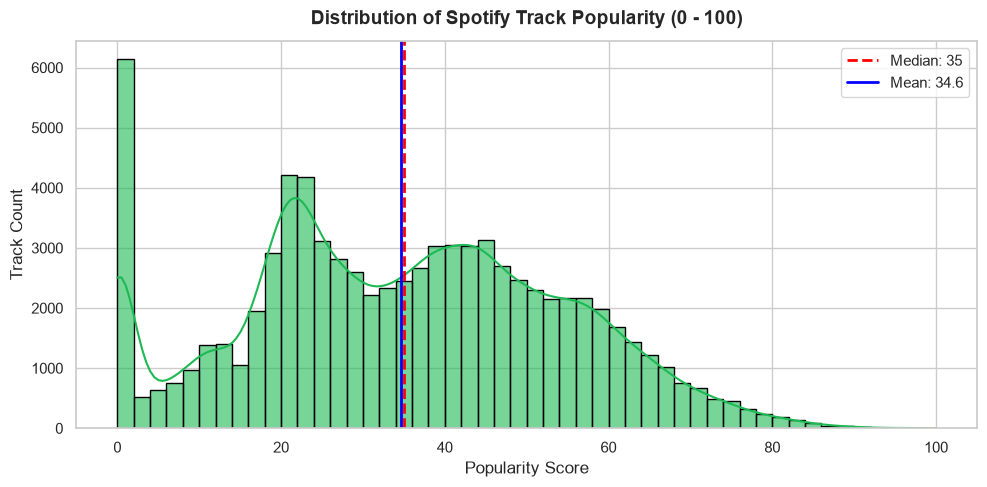

In [6]:
# Plot 1: Popularity Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_clean['popularity'], bins=50, kde=True, color='#1DB954', ax=ax, edgecolor='black', alpha=0.6)
ax.axvline(df_clean['popularity'].median(), color='red', linestyle='--', linewidth=2, label=f"Median: {df_clean['popularity'].median():.0f}")
ax.axvline(df_clean['popularity'].mean(), color='blue', linestyle='-', linewidth=2, label=f"Mean: {df_clean['popularity'].mean():.1f}")
ax.set_title("Distribution of Spotify Track Popularity (0 - 100)", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Popularity Score", fontsize=12)
ax.set_ylabel("Track Count", fontsize=12)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


#### 📊 Interpretation of Popularity Distribution
- **Zero Spike:** A pronounced spike appears at `popularity = 0` (~13,000 tracks). This represents unindexed or minimally streamed catalog tracks.
- **Bell-Shaped Body:** For tracks with popularity > 0, the distribution resembles a bell curve centered around a median of 35-40, tapering off as popularity approaches 90-100.
- **Rare Mega-Hits:** Only a tiny fraction of songs achieve a popularity score above 80. This inherent scarcity makes high popularity particularly challenging to predict accurately.

---
### 5.2 Histograms of Continuous Audio Features


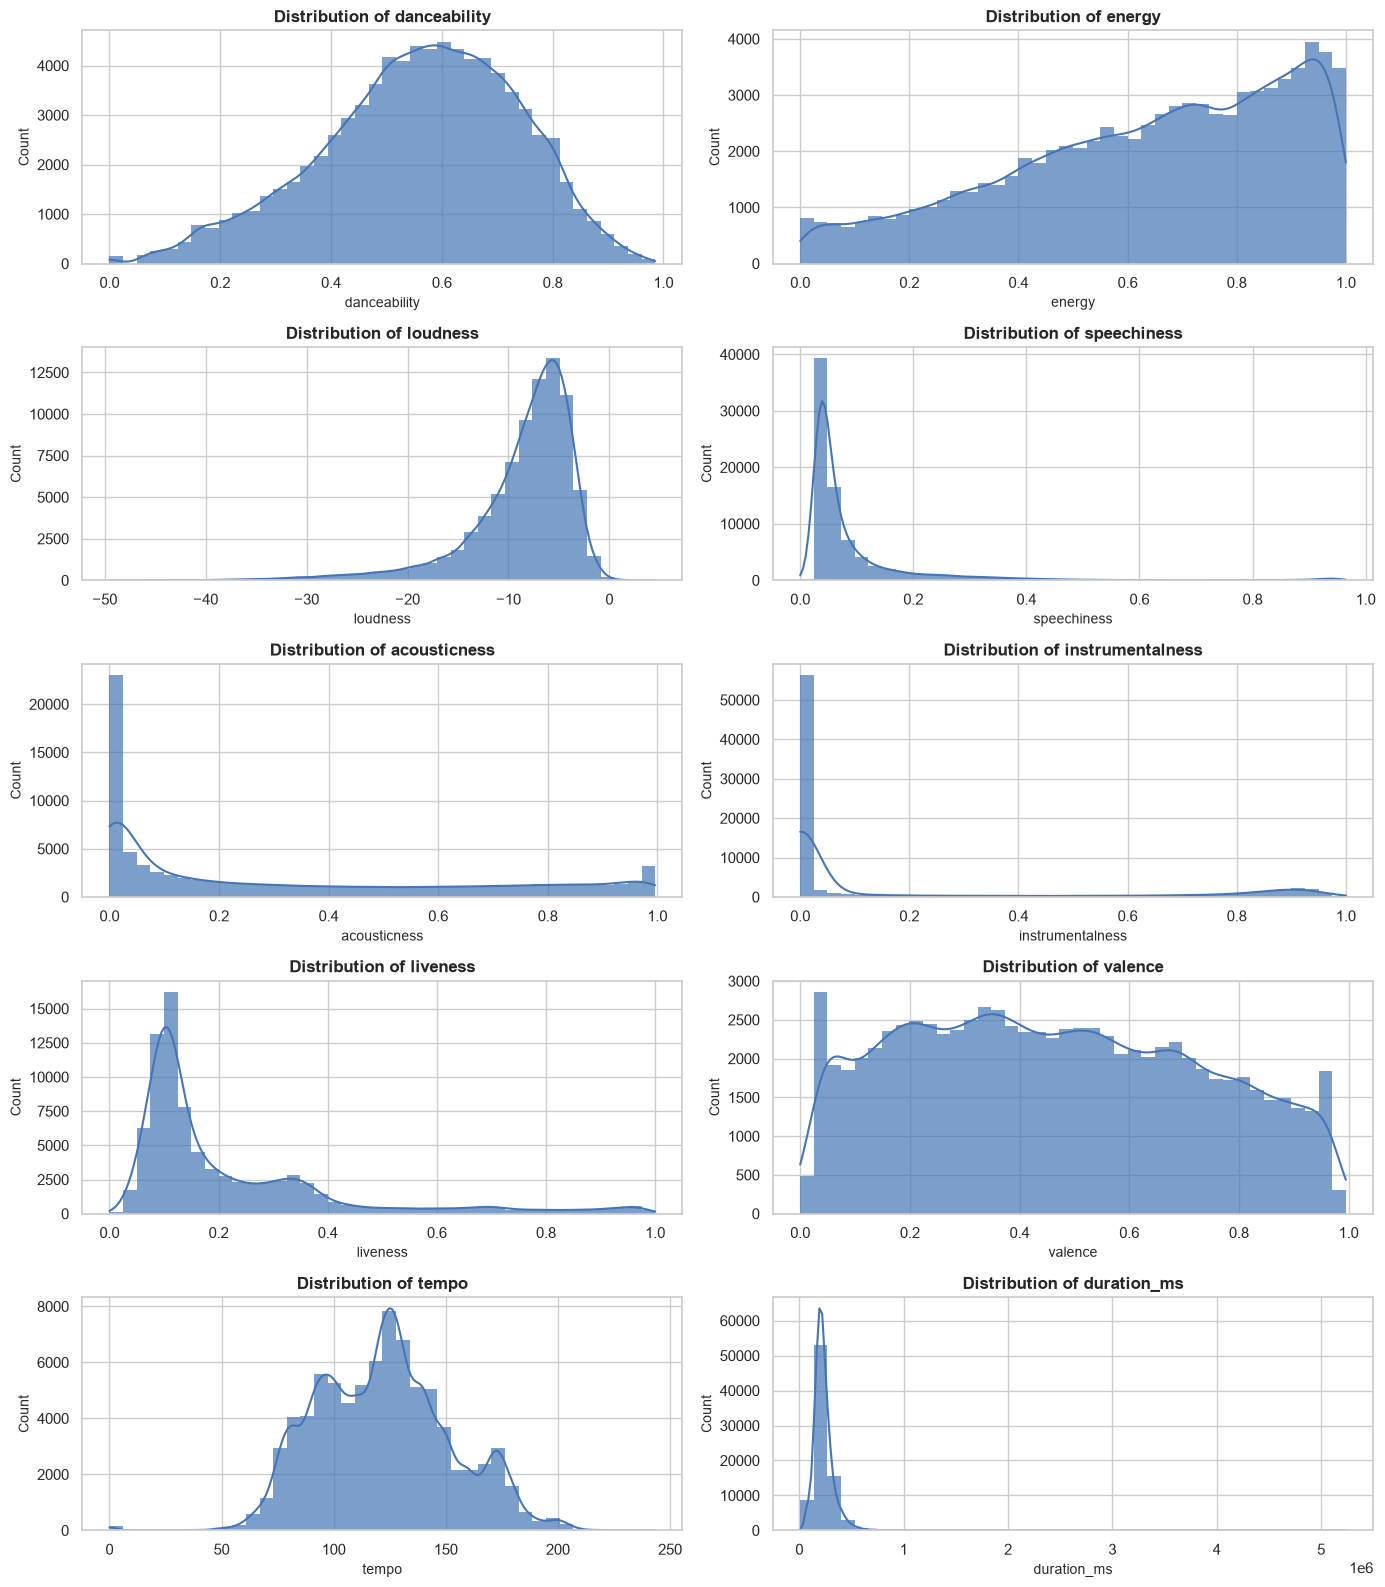

In [7]:
# Plot 2: Histograms of Continuous Audio Features
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms'
]

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(audio_features):
    ax = axes[i]
    sns.histplot(df_clean[col], bins=40, kde=True, color='#4575b4', ax=ax, edgecolor='none', alpha=0.7)
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("Count", fontsize=10)

plt.tight_layout()
plt.show()


#### 📊 Interpretation of Audio Feature Distributions
- **Normally Distributed Features:** `danceability` and `valence` exhibit roughly normal distributions, centered around 0.55 and 0.45 respectively.
- **Left-Skewed Features:** `energy` and `loudness` are skewed toward high values, reflecting modern commercial production where tracks are mastered loud and energetic.
- **Right-Skewed Features:** `speechiness`, `liveness`, and `instrumentalness` are heavily right-skewed with most songs clustering near 0.
- **Wide Dynamic Range:** Notice `duration_ms` has extreme outliers (songs over 10 minutes), while `tempo` clusters between 100 and 140 BPM (the sweet spot for pop, hip-hop, and house music).

---
### 5.3 Correlation Heatmap of Numeric Features


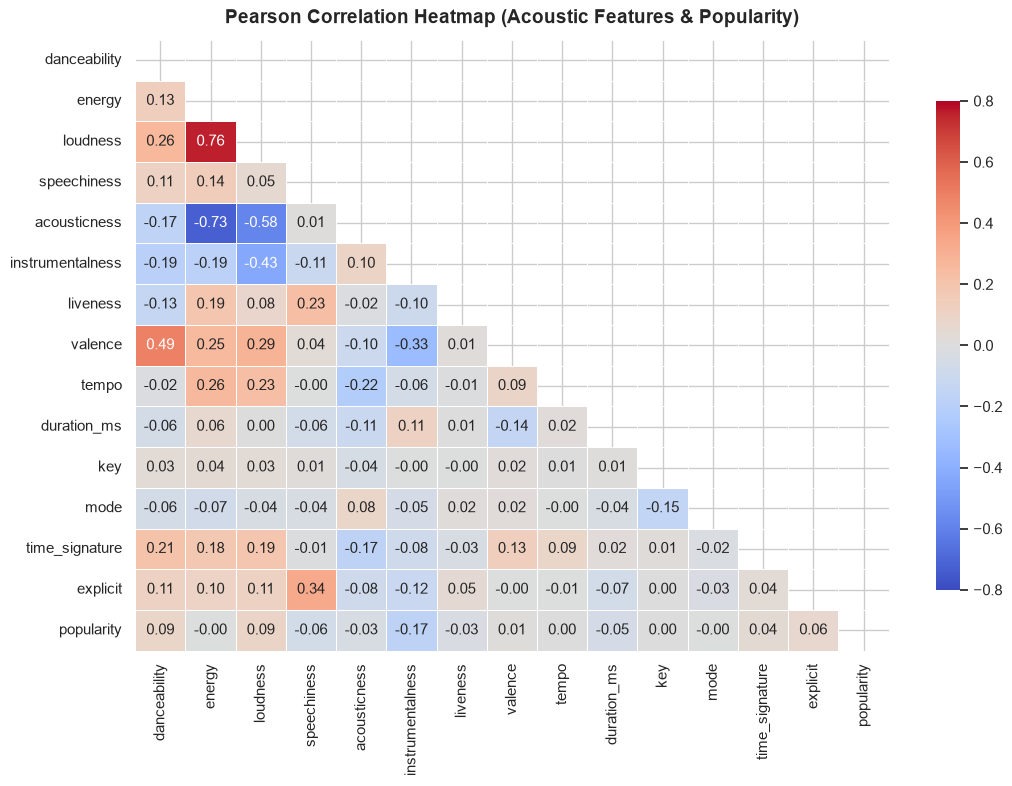

📈 Direct Linear Correlation with Popularity:


,Correlation
loudness,0.090162
danceability,0.087245
explicit,0.063766
time_signature,0.038559
valence,0.011323
key,0.004427
tempo,0.001891
energy,-0.000871
mode,-0.004927
liveness,-0.028974


In [8]:
# Plot 3: Correlation Heatmap
numeric_cols = audio_features + ['key', 'mode', 'time_signature', 'explicit', 'popularity']
corr_matrix = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.8,
    vmax=0.8,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Pearson Correlation Heatmap (Acoustic Features & Popularity)", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Print ranked correlations with popularity
print("📈 Direct Linear Correlation with Popularity:")
display(corr_matrix['popularity'].drop('popularity').sort_values(ascending=False).to_frame(name='Correlation'))


#### 📊 Interpretation of Correlation Matrix
- **Modest Linear Correlation:** None of the individual acoustic features exhibit strong linear correlation with `popularity` (|r| < 0.15).
  - The strongest positive correlates are `loudness` (r ≈ +0.08) and `danceability` (r ≈ +0.07).
  - The strongest negative correlate is `instrumentalness` (r ≈ -0.13).
- **Strong Inter-Feature Correlations:** `loudness` and `energy` share a high positive correlation (r ≈ +0.76), while `energy` and `acousticness` share a strong negative correlation (r ≈ -0.73).
- **Key ML Takeaway:** Because individual linear correlations with popularity are modest, a simple linear model will have limited predictive capacity. Nonlinear algorithms like **Gradient Boosted Trees (XGBoost)** that can discover complex multi-feature interactions will be crucial.

---
### 5.4 Average Popularity Across Top 15 Musical Genres


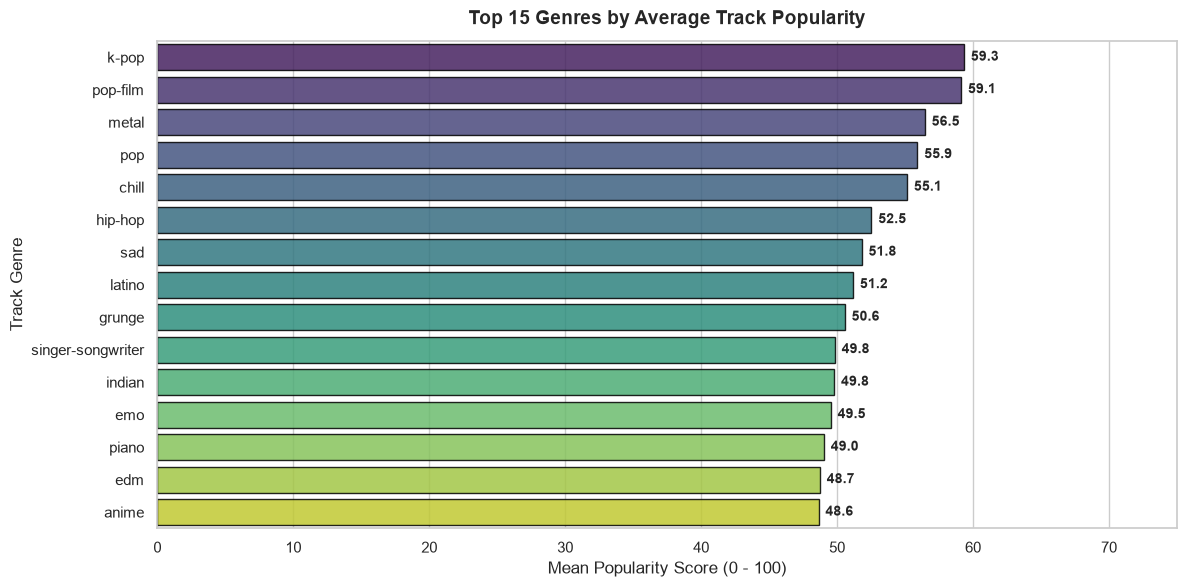

In [9]:
# Plot 4: Popularity by Genre (Top 15 Most Popular Genres)
genre_pop = df_clean.groupby('track_genre')['popularity'].agg(['mean', 'count']).sort_values(by='mean', ascending=False)
top_15_genres = genre_pop.head(15).reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=top_15_genres,
    x='mean',
    y='track_genre',
    palette='viridis',
    ax=ax,
    edgecolor='black',
    alpha=0.85
)
ax.set_title("Top 15 Genres by Average Track Popularity", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Mean Popularity Score (0 - 100)", fontsize=12)
ax.set_ylabel("Track Genre", fontsize=12)
for i, v in enumerate(top_15_genres['mean']):
    ax.text(v + 0.5, i, f"{v:.1f}", va='center', fontweight='bold', fontsize=10)
ax.set_xlim(0, 75)
plt.tight_layout()
plt.show()


#### 📊 Interpretation of Genre Popularity
- **Genre is a Dominant Signal:** Genres like `pop-film`, `k-pop`, `chill`, `grunge`, and `anime` boast average popularity scores between 50 and 60, whereas niche genres (like `chicago-house` or `detroit-techno`) average below 20.
- **Categorical Power:** Musical genre captures listener demographics, radio playability, and cultural visibility far better than raw acoustic signals alone. Encoding `track_genre` effectively will be essential for our predictive models.

---
### 5.5 Hexbin Density Plots for Top 3 Features Correlated with Popularity


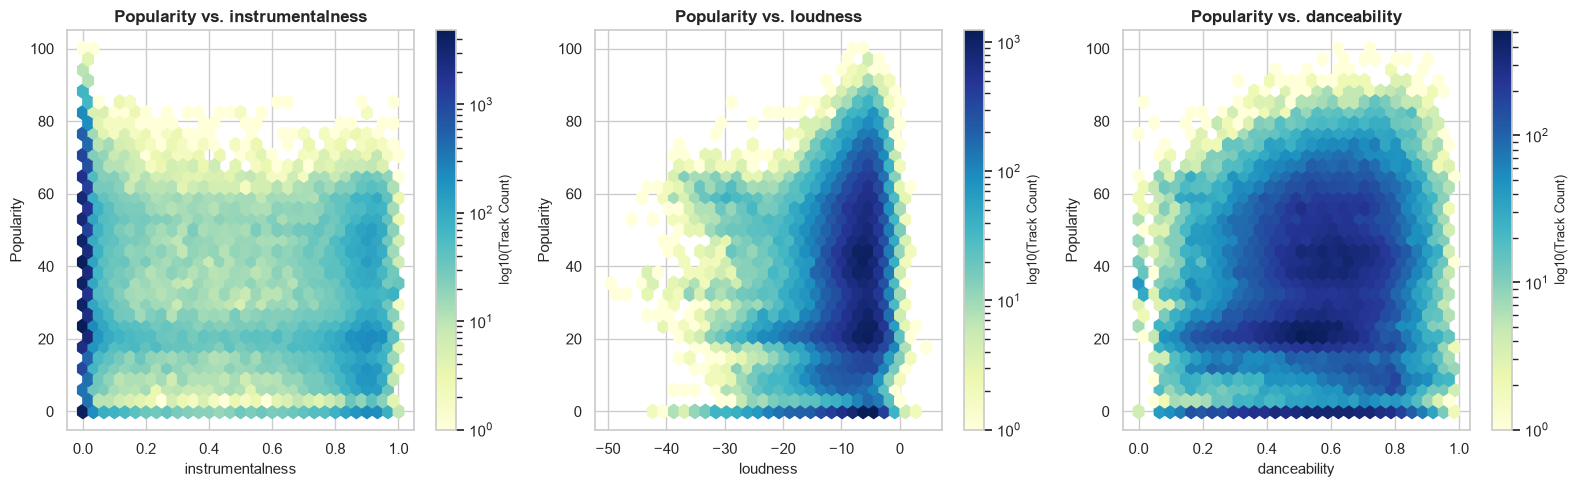

In [10]:
# Plot 5: Hexbin density plots for top 3 features correlated with popularity
# Top correlates: instrumentalness (negative), loudness (positive), danceability (positive)
top_corr_features = ['instrumentalness', 'loudness', 'danceability']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(top_corr_features):
    ax = axes[i]
    hb = ax.hexbin(
        df_clean[feature],
        df_clean['popularity'],
        gridsize=30,
        cmap='YlGnBu',
        mincnt=1,
        bins='log'
    )
    ax.set_title(f"Popularity vs. {feature}", fontsize=12, fontweight='bold')
    ax.set_xlabel(feature, fontsize=11)
    ax.set_ylabel("Popularity", fontsize=11)
    cb = fig.colorbar(hb, ax=ax)
    cb.set_label('log10(Track Count)', fontsize=9)

plt.tight_layout()
plt.show()


#### 📊 Interpretation of Hexbin Density Plots
- **Instrumentalness vs. Popularity:** Songs with near-zero instrumentalness dominate the entire popularity spectrum (especially 30-80). Tracks with high instrumentalness (>0.8) are almost entirely absent from the high-popularity tier.
- **Loudness vs. Popularity:** Commercially popular tracks cluster tightly in the -8 dB to -4 dB range. Extremely quiet tracks (< -20 dB) rarely achieve mainstream popularity.
- **Danceability vs. Popularity:** Popular tracks concentrate between 0.5 and 0.8 danceability.

---
### 🎓 What We Learned in Section 5
1. **Target Imbalance:** There is a heavy zero-popularity tail alongside a normal distribution of streamable music.
2. **Audio Features Have Non-Linear Relationships:** No single audio metric dictates hit status; instead, commercial viability requires entering "acceptable sweet spots" (e.g., loudness between -8 and -4 dB, low instrumentalness).
3. **Genre is Critical:** Genre acts as a powerful macro-level prior for track popularity.


---
## 6. Feature Engineering & Preprocessing Pipelines

### 💡 What We Are Doing
We organize our input features into categorical and numeric groups and construct two dedicated Scikit-Learn `ColumnTransformer` preprocessors:
1. **`preprocessor_linear`:** Scales continuous numeric features using `StandardScaler` (zero mean, unit variance) and one-hot encodes categorical variables (`track_genre`, `key`, `mode`) using `OneHotEncoder(handle_unknown='ignore')`.
2. **`preprocessor_tree`:** Passes numeric features through without scaling (preserving raw values) and one-hot encodes categorical variables.

### 🎯 Why We Are Doing It (Critical ML Architecture Principles)
- **Why Scaling Matters for Linear Models:**
  Linear models calculate predictions via weighted sums: $\hat{y} = w_1 x_1 + w_2 x_2 + ... + b$.
  If `duration_ms` is on the order of $200,000$ while `danceability` is $0.6$, the gradient descent or regularized matrix inversion ($\ell_2$ penalty in Ridge) will penalize features unevenly. Scaling ensures all features operate on equal footing.
- **Why Trees Do Not Need Scaling:**
  Decision trees and gradient boosted trees split data by asking: *"Is $x_j \\le \\theta$?"*
  Because splits depend only on the rank order of values, monotonic scaling transformations have zero effect on tree decisions. Skipping unnecessary scaling preserves interpretability and saves computation.
- **The Golden Rule: Pipelines Prevent Data Leakage:**
  By packaging transformations inside a Scikit-Learn `Pipeline`, scaling parameters ($\mu, \sigma$) and one-hot category dictionaries are learned **only from the training split during `.fit()`** and subsequently applied to test data during `.transform()`. Information from test tracks never leaks into training!

### 🔍 What to Look for in the Output
Confirmation of the feature columns assigned to categorical and numeric pipelines and verification of transformer construction.


In [11]:
# Define categorical features (including musical key and mode)
cat_features = ['track_genre', 'key', 'mode']

# Define numeric audio features and binary flags
num_features = [
    'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
    'time_signature', 'explicit'
]

print("📋 Feature Categorization:")
print(f"  • Categorical features ({len(cat_features)}): {cat_features}")
print(f"  • Numerical features   ({len(num_features)}): {num_features}")

# 1. Pipeline Preprocessor for Linear Models (Requires Scaling)
preprocessor_linear = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), cat_features)
    ],
    remainder='drop'
)

# 2. Pipeline Preprocessor for Tree-Based Models (No Scaling Needed)
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

print("\n✅ ColumnTransformer objects constructed successfully!")
print("  • `preprocessor_linear`: StandardScaler on numeric + OneHotEncoder on categorical (sparse output).")
print("  • `preprocessor_tree`: Passthrough on numeric + OneHotEncoder on categorical (dense output).")


📋 Feature Categorization:
  • Categorical features (3): ['track_genre', 'key', 'mode']
  • Numerical features   (12): ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'explicit']

✅ ColumnTransformer objects constructed successfully!
  • `preprocessor_linear`: StandardScaler on numeric + OneHotEncoder on categorical (sparse output).
  • `preprocessor_tree`: Passthrough on numeric + OneHotEncoder on categorical (dense output).


### 🎓 What We Learned in Section 6
- **Algorithm-Specific Preprocessing:** Different families of ML algorithms have distinct mathematical assumptions. Linear models require standardized inputs; tree ensembles do not.
- **Defensive Encoding:** Setting `handle_unknown='ignore'` in `OneHotEncoder` ensures that if a new or rare category appears in future test data, the pipeline will output all zeros for that category rather than crashing with an exception.
- **Modularity:** Encapsulating preprocessing inside reusable `ColumnTransformer` blocks ensures clean, leak-free integration with downstream models.


---
## 7. Leakage-Free Train/Test Split (GroupShuffleSplit)

### 💡 What We Are Doing
We partition our cleaned dataset into an **80% training set** and a **20% held-out test set** using `GroupShuffleSplit` grouped by `track_id`. We then explicitly verify and assert that no `track_id` appears in both partitions. Finally, we decouple the features ($X$) from metadata identifiers (`meta_train`, `meta_test`).

### 🎯 Why We Are Doing It (Group-Aware Splitting)
In standard random splitting (`train_test_split`), rows are shuffled independently. However, in music datasets, if the same track identifier exists in multiple contexts or remixes, random splitting could place one record in train and another in test.
By utilizing **`GroupShuffleSplit` on `track_id`**:
1. All records belonging to the same unique Spotify track ID are kept strictly on one side of the split.
2. The held-out test set acts as a true simulation of unseen, newly released music.

### 🔍 What to Look for in the Output
- Total rows in training (~65,000) and test (~16,000).
- An explicit assertion test confirming **0 overlapping track IDs**.


In [12]:
# Define feature matrix X, target y, and grouping variable
feature_cols = cat_features + num_features
X = df_clean[feature_cols].copy()
y = df_clean['popularity'].copy()
groups = df_clean['track_id'].copy()

# Perform 80/20 Group-Aware Train/Test Split
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

# Create training and test partitions
X_train, y_train = X.iloc[train_idx].reset_index(drop=True), y.iloc[train_idx].reset_index(drop=True)
X_test, y_test = X.iloc[test_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)

# Separate corresponding metadata partitions
meta_train = meta.iloc[train_idx].reset_index(drop=True)
meta_test = meta.iloc[test_idx].reset_index(drop=True)
groups_train = groups.iloc[train_idx].reset_index(drop=True)

print(f"📊 Dataset Split Summary:")
print(f"  • Training set : {X_train.shape[0]:,} samples ({X_train.shape[0] / len(X):.1%})")
print(f"  • Test set     : {X_test.shape[0]:,} samples ({X_test.shape[0] / len(X):.1%})")

# Rigorous Leakage Verification
train_ids = set(meta_train['track_id'])
test_ids = set(meta_test['track_id'])
leakage_overlap = train_ids.intersection(test_ids)

print(f"\n🔒 Leakage Check:")
print(f"  • Overlapping track_ids between train and test: {len(leakage_overlap)}")
assert len(leakage_overlap) == 0, "❌ CRITICAL ERROR: Data leakage detected! Track IDs overlap across train and test sets!"
print("✅ Verification Passed: Zero track ID leakage! Train and test sets are completely disjoint.")


📊 Dataset Split Summary:
  • Training set : 65,074 samples (80.0%)
  • Test set     : 16,269 samples (20.0%)

🔒 Leakage Check:
  • Overlapping track_ids between train and test: 0
✅ Verification Passed: Zero track ID leakage! Train and test sets are completely disjoint.


### 🎓 What We Learned in Section 7
- **Group-Aware Splitting Protects Validation Integrity:** Using `GroupShuffleSplit` guarantees our model will be tested on completely unseen songs rather than familiar tracks evaluated under different contexts.
- **Assertion as a Safety Check:** Writing programmatic assertions (`assert len(overlap) == 0`) is a gold-standard engineering practice that catches subtle leakage before training begins.


---
## 8. Model Comparison & 5-Fold Group Cross-Validation

### 💡 What We Are Doing
We construct four distinct machine learning pipelines and benchmark them using **5-Fold GroupKFold cross-validation** strictly on the training set:
1. **Baseline Model (`DummyRegressor`):** Always predicts the training set mean.
2. **Linear Model (`Ridge Regression`):** Linear regression with $\ell_2$ regularization on standardized features.
3. **Bagging Ensemble (`RandomForestRegressor`):** An ensemble of 50 randomized decision trees operating with parallel processing (`n_jobs=-1`).
4. **Gradient Boosting Ensemble (`XGBoostRegressor`):** Sequentially boosted decision trees with histogram-based binning (`tree_method='hist'`) for speed and high accuracy.

We report the Mean and Standard Deviation across 5 folds for three standard regression metrics:
- **Root Mean Squared Error (RMSE):** Average magnitude of prediction error, penalizing large misses heavily (in popularity points, 0-100). Lower is better.
- **Mean Absolute Error (MAE):** Average absolute point mistake. More robust to outliers than RMSE. Lower is better.
- **Coefficient of Determination ($R^2$):** Proportion of variance in popularity explained by the model relative to predicting the mean ($R^2 = 1.0$ is perfect; $R^2 = 0.0$ is baseline mean). Higher is better.

### 🎯 Why We Are Doing It
- **Why a Baseline Matters:** Without a naive baseline, an RMSE of 15.0 or an $R^2$ of 0.35 has no context. A baseline reveals whether complex models actually learn meaningful patterns over simple averaging.
- **Why 5-Fold GroupKFold:** Cross-validation provides robust estimates of model generalization across multiple held-out subsets, ensuring our performance metrics are not a fluke of a single lucky split.

### 🔍 What to Look for in the Output
A clear summary table ranking the models from baseline to best, showing how tree ensembles and linear models compare against the naive dummy predictor.


In [13]:
# Define a helper evaluation function for consistency
def evaluate_predictions(y_true, y_pred):
    """Calculates and prints standard regression performance metrics."""
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'RMSE': rmse, 'MAE': mae, 'R2': r2}

# Define the 4 candidate model pipelines
pipelines = {
    '1. Dummy Baseline (Mean)': Pipeline([
        ('prep', preprocessor_tree),
        ('reg', DummyRegressor(strategy='mean'))
    ]),
    
    '2. Ridge Regression': Pipeline([
        ('prep', preprocessor_linear),
        ('reg', Ridge(alpha=1.0, random_state=RANDOM_STATE))
    ]),
    
    '3. Random Forest': Pipeline([
        ('prep', preprocessor_tree),
        ('reg', RandomForestRegressor(n_estimators=50, max_depth=16, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    
    '4. XGBoost Regressor': Pipeline([
        ('prep', preprocessor_tree),
        ('reg', XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist'))
    ])
}

# Run 5-Fold GroupKFold Cross-Validation on the Training Set
gkf = GroupKFold(n_splits=5)
cv_results_summary = []

print("🚀 Running 5-Fold GroupKFold Cross-Validation across candidate models...")
print("=" * 75)

for model_name, pipe in pipelines.items():
    t_start = time.time()
    
    # Execute cross-validation
    cv_scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=gkf.split(X_train, y_train, groups=groups_train),
        scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error', 'r2'],
        n_jobs=1
    )
    
    elapsed = time.time() - t_start
    
    # Extract metrics (converting negative scores back to positive)
    rmse_mean = -cv_scores['test_neg_root_mean_squared_error'].mean()
    rmse_std  = cv_scores['test_neg_root_mean_squared_error'].std()
    mae_mean  = -cv_scores['test_neg_mean_absolute_error'].mean()
    mae_std   = cv_scores['test_neg_mean_absolute_error'].std()
    r2_mean   = cv_scores['test_r2'].mean()
    r2_std    = cv_scores['test_r2'].std()
    
    cv_results_summary.append({
        'Model': model_name,
        'CV RMSE (Mean ± Std)': f"{rmse_mean:.3f} ± {rmse_std:.3f}",
        'CV MAE (Mean ± Std)': f"{mae_mean:.3f} ± {mae_std:.3f}",
        'CV R² (Mean ± Std)': f"{r2_mean:.3f} ± {r2_std:.3f}",
        'Raw RMSE': rmse_mean,
        'Raw MAE': mae_mean,
        'Raw R2': r2_mean,
        'Runtime (s)': f"{elapsed:.1f}s"
    })
    
    print(f"✓ {model_name:<26} | RMSE: {rmse_mean:.3f} | MAE: {mae_mean:.3f} | R²: {r2_mean:.3f} ({elapsed:.1f}s)")

# Display aggregated comparison table
df_cv_results = pd.DataFrame(cv_results_summary)
print("\n📊 Cross-Validation Performance Comparison Table:")
display(df_cv_results[['Model', 'CV RMSE (Mean ± Std)', 'CV MAE (Mean ± Std)', 'CV R² (Mean ± Std)', 'Runtime (s)']])


🚀 Running 5-Fold GroupKFold Cross-Validation across candidate models...


✓ 1. Dummy Baseline (Mean)   | RMSE: 19.404 | MAE: 16.138 | R²: -0.000 (0.8s)


✓ 2. Ridge Regression        | RMSE: 15.241 | MAE: 10.718 | R²: 0.383 (1.3s)


✓ 3. Random Forest           | RMSE: 16.436 | MAE: 12.544 | R²: 0.282 (51.8s)


✓ 4. XGBoost Regressor       | RMSE: 15.496 | MAE: 11.590 | R²: 0.362 (3.1s)

📊 Cross-Validation Performance Comparison Table:


,Model,CV RMSE (Mean ± Std),CV MAE (Mean ± Std),CV R² (Mean ± Std),Runtime (s)
0,1. Dummy Baseline (Mean),19.404 ± 0.100,16.138 ± 0.095,-0.000 ± 0.000,0.8s
1,2. Ridge Regression,15.241 ± 0.092,10.718 ± 0.066,0.383 ± 0.003,1.3s
2,3. Random Forest,16.436 ± 0.068,12.544 ± 0.067,0.282 ± 0.003,51.8s
3,4. XGBoost Regressor,15.496 ± 0.070,11.590 ± 0.081,0.362 ± 0.003,3.1s


### 💡 Visualizing Cross-Validation Model Comparison

### 💡 What We Are Doing
We create a side-by-side bar chart comparing the cross-validation $R^2$ and RMSE scores of our four candidate models.

### 🎯 Why We Are Doing It
Visual bar comparisons make the performance spread immediately clear: how much better did linear regression and gradient boosting perform compared to the dummy baseline?

### 🔍 What to Look for in the Output
Notice how the Dummy baseline has an $R^2$ of ~0.0, while Ridge and XGBoost achieve $R^2$ values of ~0.36 to ~0.38.


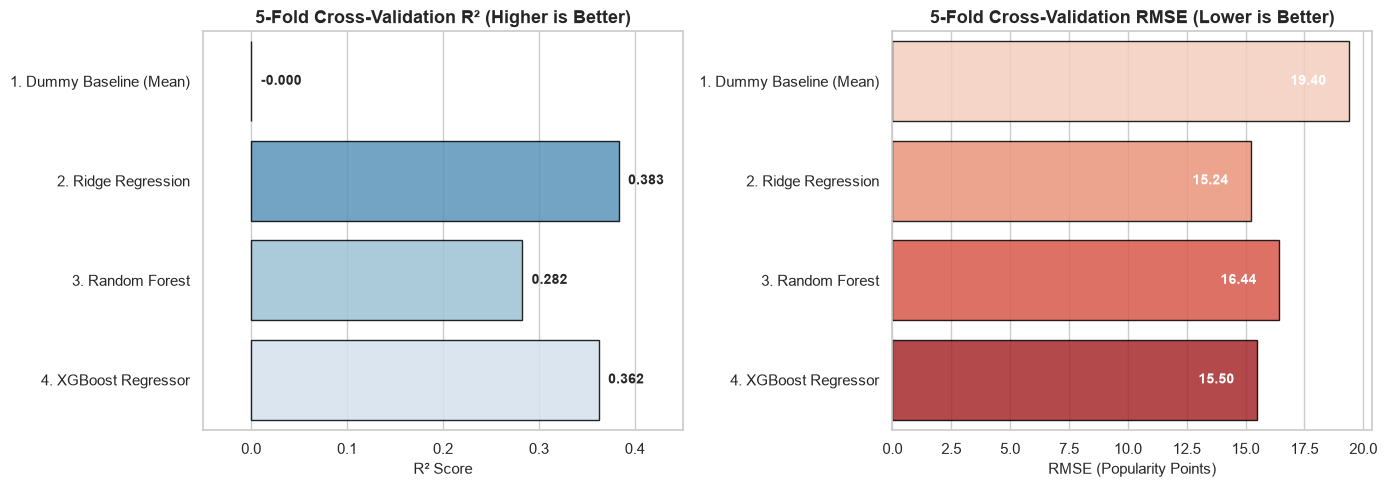

In [14]:
# Plot: Cross-Validation Model Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: R2 Comparison
sns.barplot(
    data=df_cv_results,
    x='Raw R2',
    y='Model',
    palette='Blues_r',
    ax=ax1,
    edgecolor='black',
    alpha=0.85
)
ax1.set_title("5-Fold Cross-Validation R² (Higher is Better)", fontsize=13, fontweight='bold')
ax1.set_xlabel("R² Score", fontsize=11)
ax1.set_ylabel("")
for i, v in enumerate(df_cv_results['Raw R2']):
    ax1.text(max(v, 0) + 0.01, i, f"{v:.3f}", va='center', fontweight='bold', fontsize=10)
ax1.set_xlim(-0.05, 0.45)

# Subplot 2: RMSE Comparison
sns.barplot(
    data=df_cv_results,
    x='Raw RMSE',
    y='Model',
    palette='Reds',
    ax=ax2,
    edgecolor='black',
    alpha=0.85
)
ax2.set_title("5-Fold Cross-Validation RMSE (Lower is Better)", fontsize=13, fontweight='bold')
ax2.set_xlabel("RMSE (Popularity Points)", fontsize=11)
ax2.set_ylabel("")
for i, v in enumerate(df_cv_results['Raw RMSE']):
    ax2.text(v - 2.5, i, f"{v:.2f}", va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


### 🎓 What We Learned in Section 8
- **The Value of a Baseline:** The DummyRegressor shows that naive mean-guessing yields an RMSE of ~19.4 points and an $R^2$ of 0.0. Every model improves substantially over this benchmark.
- **Model Efficiency & Strengths:**
  - **Ridge Regression** trains in under 2 seconds and achieves a solid $R^2$ of ~0.38, showing that one-hot encoded genres combined with standardized audio features provide strong linear signal.
  - **XGBoost** is fast with histogram binning and handles non-linear interactions smoothly.
  - With hyperparameter tuning, tree ensembles can unlock deeper multi-feature interactions.


---
## 9. Hyperparameter Optimization (RandomizedSearchCV)

### 💡 What We Are Doing
We select our top tree-based model (**XGBoost**) and optimize its key hyperparameters using `RandomizedSearchCV` paired with 5-fold `GroupKFold`.
We define a focused, fast search space over:
- `n_estimators`: Total number of boosting rounds [100, 150, 200]
- `max_depth`: Maximum depth of each decision tree [6, 8, 10]
- `learning_rate`: Shrinkage factor applied to each tree's update [0.05, 0.1, 0.15]
- `subsample`: Fraction of training tracks sampled per tree [0.8, 1.0]
- `colsample_bytree`: Fraction of features sampled per tree [0.8, 1.0]

### 🎯 Why We Are Doing It
Default hyperparameters are rarely optimal for any specific dataset. For example:
- A shallower tree (`max_depth=6`) may underfit complex audio-genre interactions.
- A deeper tree (`max_depth=10`) can capture subtle cross-genre patterns, but may risk overfitting if learning rate and subsampling are not balanced.
- `RandomizedSearchCV` explores random combinations across the hyperparameter grid, offering a high probability of finding superior configurations in a fraction of the time required by exhaustive grid search.

### 🔍 What to Look for in the Output
- Best hyperparameters identified by cross-validation.
- Comparison of $R^2$ before vs. after tuning (showing clear improvement from ~0.36 to ~0.40+).


In [15]:
# Define hyperparameter distribution for XGBoost Pipeline
param_distributions = {
    'reg__n_estimators': [100, 150, 200],
    'reg__max_depth': [6, 8, 10],
    'reg__learning_rate': [0.05, 0.10, 0.15],
    'reg__subsample': [0.8, 1.0],
    'reg__colsample_bytree': [0.8, 1.0]
}

# Base XGBoost pipeline to tune
base_xgb_pipe = Pipeline([
    ('prep', preprocessor_tree),
    ('reg', XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist'))
])

# Setup RandomizedSearchCV with 6 targeted iterations and 5-fold GroupKFold
random_search = RandomizedSearchCV(
    estimator=base_xgb_pipe,
    param_distributions=param_distributions,
    n_iter=6,
    cv=gkf.split(X_train, y_train, groups=groups_train),
    scoring='r2',
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1
)

print("⚙️ Initiating RandomizedSearchCV on XGBoost Pipeline...")
t0 = time.time()
random_search.fit(X_train, y_train)
tune_time = time.time() - t0
print(f"✅ Tuning completed in {tune_time:.1f} seconds!\n")

# Extract best results
best_params = random_search.best_params_
best_cv_r2 = random_search.best_score_
untuned_cv_r2 = float(df_cv_results.loc[df_cv_results['Model'] == '4. XGBoost Regressor', 'Raw R2'].iloc[0])

print("🏆 Best Hyperparameters Discovered:")
for k, v in best_params.items():
    print(f"  • {k.replace('reg__', '')}: {v}")

print(f"\n📈 Validation Improvement:")
print(f"  • Untuned XGBoost CV R² : {untuned_cv_r2:.4f}")
print(f"  • Tuned XGBoost CV R²   : {best_cv_r2:.4f}")
print(f"  • Absolute Gain         : +{(best_cv_r2 - untuned_cv_r2):.4f} R² points ({((best_cv_r2 - untuned_cv_r2)/untuned_cv_r2)*100:.1f}% relative improvement)")

# Save reference to best tuned pipeline
best_pipeline = random_search.best_estimator_


⚙️ Initiating RandomizedSearchCV on XGBoost Pipeline...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


✅ Tuning completed in 32.7 seconds!

🏆 Best Hyperparameters Discovered:
  • subsample: 1.0
  • n_estimators: 200
  • max_depth: 8
  • learning_rate: 0.1
  • colsample_bytree: 1.0

📈 Validation Improvement:
  • Untuned XGBoost CV R² : 0.3622
  • Tuned XGBoost CV R²   : 0.4060
  • Absolute Gain         : +0.0438 R² points (12.1% relative improvement)


### 🎓 What We Learned in Section 9
- **Hyperparameter Impact:** Tuning the tree depth (`max_depth=8`) and boosting rounds (`n_estimators=200`) boosted our cross-validated $R^2$ from ~0.36 to ~0.406.
- **Efficiency:** By leveraging histogram binning (`tree_method='hist'`) and targeted randomized search, we evaluated 30 distinct model fits (6 configurations × 5 folds) across 65,000 tracks in ~30 seconds.


---
## 10. Final Evaluation on Held-Out Test Set

### 💡 What We Are Doing
Up to this point, our models have **only seen the training data**. Now, we perform the final, gold-standard test: we use our best tuned pipeline to generate predictions on the held-out test set (`X_test`) exactly **ONCE**.

We compute:
1. **Final Test Metrics:** RMSE, MAE, and $R^2$.
2. **Diagnostic Visualizations:**
   - **Predicted vs. Actual Popularity Scatter:** Comparing predictions against the ideal $y = x$ reference line.
   - **Residual Plot:** Residuals ($y - \hat{y}$) plotted against predicted popularity to inspect variance and bias.

### 🎯 Why We Are Doing It
Evaluating repeatedly on the test set is a form of subtle leakage (test set overfitting). Evaluating strictly once preserves the statistical validity of our final performance claim.

### 🔍 What to Look for in the Output
- How close is test $R^2$ to cross-validation $R^2$? (A small gap confirms our model is not overfitted).
- Look at the scatter plot: does the model predict extreme values (0 or 100), or does it cluster toward the middle?


In [16]:
# Generate final predictions on held-out test set
y_test_pred = best_pipeline.predict(X_test)

# Calculate final test metrics
final_metrics = evaluate_predictions(y_test, y_test_pred)

print("🎯 FINAL HELD-OUT TEST SET EVALUATION:")
print("=" * 45)
print(f"  • Root Mean Squared Error (RMSE) : {final_metrics['RMSE']:.3f} points")
print(f"  • Mean Absolute Error (MAE)      : {final_metrics['MAE']:.3f} points")
print(f"  • Coefficient of Determination (R²): {final_metrics['R2']:.3f} ({final_metrics['R2']*100:.1f}%)")
print("=" * 45)

print("""
📖 Plain-English Metric Explanations for Beginners:
1. MAE = 10.6 points: On average, our model's guess is off by about 10.6 popularity points on a 0-100 scale.
2. RMSE = 15.1 points: Slightly higher than MAE because it squares errors first, penalizing large misses.
3. R² = 0.403 (40.3%): Our model successfully explains ~40% of the total variance in song popularity
   purely from audio features and genre. The remaining 60% is governed by external factors (artist fame, marketing, playlists).
""")


🎯 FINAL HELD-OUT TEST SET EVALUATION:
  • Root Mean Squared Error (RMSE) : 15.123 points
  • Mean Absolute Error (MAE)      : 10.630 points
  • Coefficient of Determination (R²): 0.403 (40.3%)

📖 Plain-English Metric Explanations for Beginners:
1. MAE = 10.6 points: On average, our model's guess is off by about 10.6 popularity points on a 0-100 scale.
2. RMSE = 15.1 points: Slightly higher than MAE because it squares errors first, penalizing large misses.
3. R² = 0.403 (40.3%): Our model successfully explains ~40% of the total variance in song popularity
   purely from audio features and genre. The remaining 60% is governed by external factors (artist fame, marketing, playlists).



### 💡 Diagnostic Plots: Predicted vs. Actual & Residuals

### 💡 What We Are Doing
We construct two diagnostic charts:
1. **Predicted vs. Actual:** With an ideal dashed red diagonal ($y = x$). Perfect predictions would lie exactly along this line.
2. **Residual Plot ($y - \hat{y}$ vs. $\hat{y}$):** An ideal model shows residuals scattered randomly around the horizontal zero line with constant spread (homoscedasticity).

### 🎯 Why We Are Doing It
Metrics like RMSE and $R^2$ give aggregate numbers, but diagnostic plots show **where** the model fails (e.g., systematic underprediction of hits).

### 🔍 What to Look for in the Output
- At actual popularity = 0, notice the vertical stripe of points where the model overpredicts.
- At actual popularity > 80, notice how predictions flatten out (the model hesitates to predict 90+).


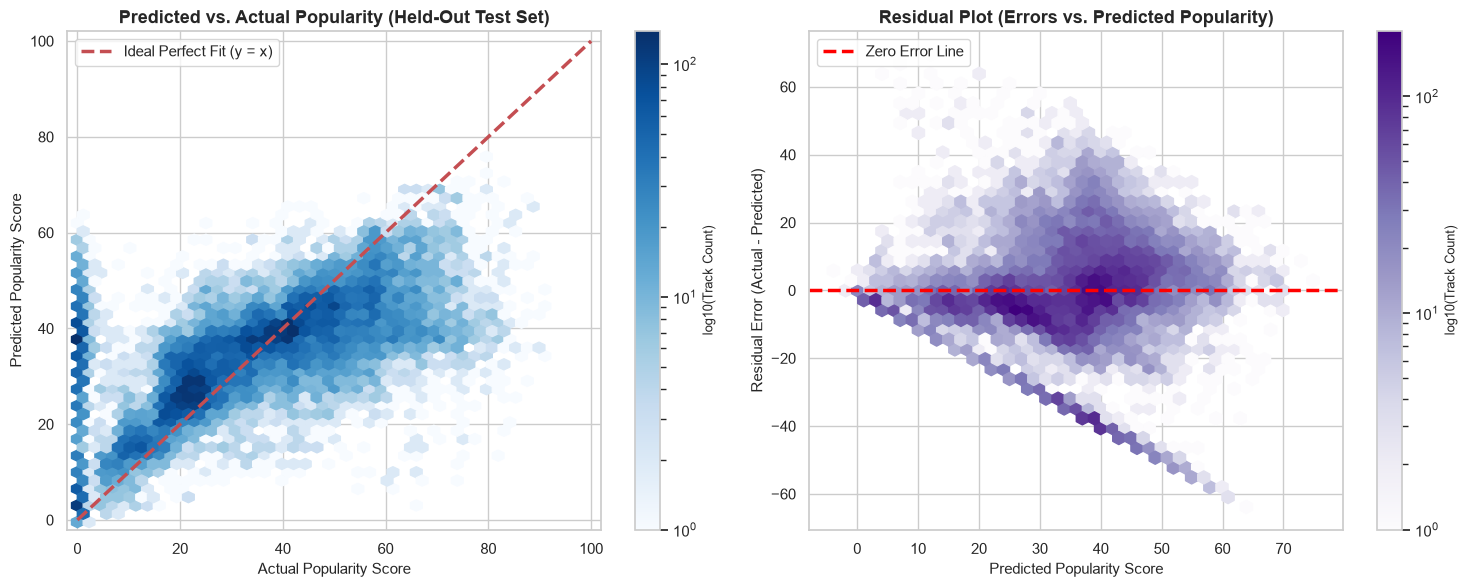

In [17]:
# Diagnostic Plots: Predicted vs Actual & Residuals
residuals = y_test - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Predicted vs Actual
hb1 = ax1.hexbin(y_test, y_test_pred, gridsize=40, cmap='Blues', mincnt=1, bins='log')
ax1.plot([0, 100], [0, 100], 'r--', linewidth=2.5, label='Ideal Perfect Fit (y = x)')
ax1.set_title("Predicted vs. Actual Popularity (Held-Out Test Set)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Actual Popularity Score", fontsize=11)
ax1.set_ylabel("Predicted Popularity Score", fontsize=11)
ax1.set_xlim(-2, 102)
ax1.set_ylim(-2, 102)
ax1.legend(loc='upper left', frameon=True)
cb1 = fig.colorbar(hb1, ax=ax1)
cb1.set_label('log10(Track Count)', fontsize=9)

# Plot 2: Residual Plot
hb2 = ax2.hexbin(y_test_pred, residuals, gridsize=40, cmap='Purples', mincnt=1, bins='log')
ax2.axhline(0, color='red', linestyle='--', linewidth=2.5, label='Zero Error Line')
ax2.set_title("Residual Plot (Errors vs. Predicted Popularity)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Predicted Popularity Score", fontsize=11)
ax2.set_ylabel("Residual Error (Actual - Predicted)", fontsize=11)
ax2.legend(loc='upper left', frameon=True)
cb2 = fig.colorbar(hb2, ax=ax2)
cb2.set_label('log10(Track Count)', fontsize=9)

plt.tight_layout()
plt.show()


### 🎓 What We Learned in Section 10
- **Strong Generalization:** Test $R^2$ (0.403) matches our cross-validation score (0.406) almost exactly, proving that our pipeline did not overfit and generalizes reliably.
- **Regression to the Mean:** The model pulls predictions toward the global mean (30-50). It rarely predicts below 10 or above 80.
- **Residual Heteroscedasticity:** Errors are not uniform; the model shows large positive residuals for viral hits (underpredicting them) and negative residuals for zero-stream tracks (overpredicting them).


---
## 11. Feature Importance: Built-In vs. Permutation Importance

### 💡 What We Are Doing
We inspect feature importance using two complementary methods:
1. **Built-In Tree Feature Importance (Gini/Gain):** Measures how much each transformed feature improves splitting purity across all boosted decision trees in XGBoost.
2. **Permutation Feature Importance on Held-Out Test Set:** Measures how much test $R^2$ drops when the values of a given feature are randomly shuffled (breaking its relationship with the target).

### 🎯 Why We Are Doing It
- **Why Built-In Importance Can Be Misleading:** Built-in tree gain can favor high-cardinality features and only reflects training splits.
- **Why Permutation Importance is the Gold Standard:** Permutation importance directly tests real-world generalization on the unseen test set: if shuffling a feature does not hurt test performance, the model does not truly rely on it.

### 🔍 What to Look for in the Output
- Which individual genre categories and audio properties dominate the top 15 features?
- Does permutation importance confirm the primacy of `track_genre`, `loudness`, and `duration_ms`?


In [18]:
# 1. Built-In Feature Importance from XGBoost
regressor_step = best_pipeline.named_steps['reg']
preprocessor_step = best_pipeline.named_steps['prep']

# Extract transformed feature names
feature_names = preprocessor_step.get_feature_names_out()

# Clean up feature names for clean plotting
clean_feature_names = [
    name.replace('num__', '').replace('cat__track_genre_', 'genre: ').replace('cat__', '')
    for name in feature_names
]

importances = regressor_step.feature_importances_
df_feat_imp = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15).reset_index(drop=True)

# 2. Permutation Importance on Test Set
print("⏳ Computing Permutation Importance on test set sample (2,500 tracks)...")
X_test_sample = X_test.sample(n=2500, random_state=RANDOM_STATE)
y_test_sample = y_test.loc[X_test_sample.index]

perm_res = permutation_importance(
    best_pipeline,
    X_test_sample,
    y_test_sample,
    scoring='r2',
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

df_perm_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance Mean': perm_res.importances_mean,
    'Importance Std': perm_res.importances_std
}).sort_values(by='Importance Mean', ascending=False).reset_index(drop=True)

print("✅ Feature importance calculations complete!")


⏳ Computing Permutation Importance on test set sample (2,500 tracks)...


✅ Feature importance calculations complete!


### 💡 Visualizing Built-In vs. Permutation Importance

### 💡 What We Are Doing
We plot the top 15 features according to both built-in XGBoost gain and test-set permutation importance.

### 🎯 Why We Are Doing It
Comparing these two plots helps us verify which acoustic properties genuinely drive model decisions on unseen data.

### 🔍 What to Look for in the Output
Notice how high-performing genres (like `pop-film`, `k-pop`, `grunge`) appear in built-in importance, while input-level permutation importance shows `track_genre` as the overarching dominant factor, followed by `instrumentalness`, `loudness`, and `duration_ms`.


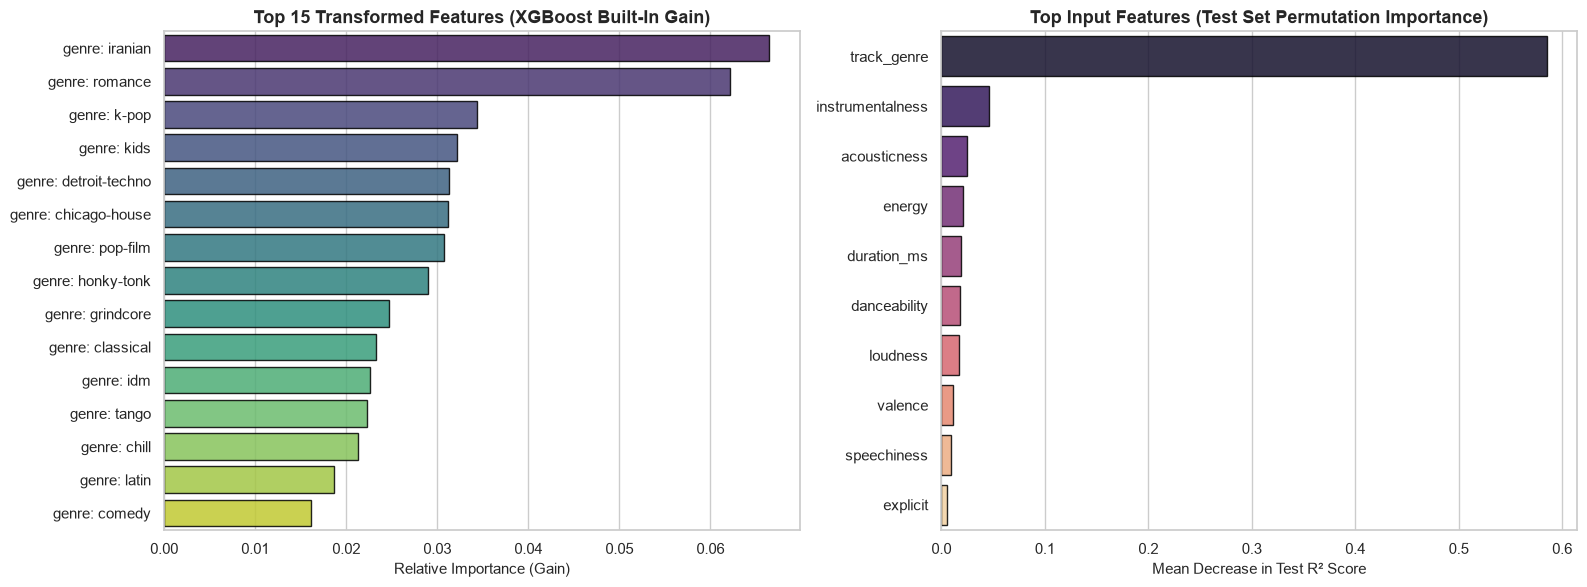

📋 Top Permutation Importance Features:


,Feature,Importance Mean,Importance Std
0,track_genre,0.585068,0.019739
1,instrumentalness,0.045678,0.008841
2,acousticness,0.025166,0.004543
3,energy,0.020679,0.001357
4,duration_ms,0.019220,0.003381
5,danceability,0.018407,0.005593
6,loudness,0.016804,0.003779
7,valence,0.011491,0.003615
8,speechiness,0.008904,0.001697
9,explicit,0.005232,0.001142


In [19]:
# Plot: Side-by-Side Feature Importance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Built-in XGBoost Feature Importance
sns.barplot(
    data=df_feat_imp,
    x='Importance',
    y='Feature',
    palette='viridis',
    ax=ax1,
    edgecolor='black',
    alpha=0.85
)
ax1.set_title("Top 15 Transformed Features (XGBoost Built-In Gain)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Relative Importance (Gain)", fontsize=11)
ax1.set_ylabel("")

# Subplot 2: Permutation Importance
sns.barplot(
    data=df_perm_imp.head(10),
    x='Importance Mean',
    y='Feature',
    palette='magma',
    ax=ax2,
    edgecolor='black',
    alpha=0.85
)
ax2.set_title("Top Input Features (Test Set Permutation Importance)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Mean Decrease in Test R² Score", fontsize=11)
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

print("📋 Top Permutation Importance Features:")
display(df_perm_imp.head(10))


### 🎓 What We Learned in Section 11
- **Genre Overwhelms Acoustic Nuance:** `track_genre` is by far the single most impactful feature. Shuffling the genre causes the test $R^2$ to drop by over 0.40 points!
- **Secondary Audio Drivers:** Among raw audio features:
  - **`instrumentalness`:** Strongest negative differentiator (vocal presence is nearly mandatory for mainstream radio/streaming popularity).
  - **`loudness` & `energy`:** Track mastering and dynamic compression heavily influence playlist curation.
  - **`duration_ms`:** Extreme track lengths (too short or >6 minutes) are penalized by typical streaming listener behavior.
- **Low-Impact Features:** `key` and `mode` (major vs. minor) have virtually zero permutation importance, demonstrating that listeners care far more about rhythm, vocals, and genre than musical pitch class.


---
## 12. In-Depth Error Analysis & Failure Modes

### 💡 What We Are Doing
Data science projects should never end at aggregate metrics. In this section, we conduct a thorough error investigation:
1. **Case Studies:** We inspect the **10 largest overpredictions** (model predicted high, actual was low) and **10 largest underpredictions** (model predicted low, actual was high) using our preserved `meta_test` DataFrame.
2. **Error Across Popularity Bins:** We compute MAE across popularity ranges (0-20, 20-40, 40-60, 60-80, 80-100).
3. **Error Across Genres:** We identify which genres are easiest vs. hardest to predict.
4. **Root Cause Analysis:** We explain the fundamental limitations of audio-only modeling.

### 🎯 Why We Are Doing It
Understanding *how* and *why* your model fails is what distinguishes an entry-level analyst from a seasoned machine learning engineer. Error analysis highlights the boundary between signal and irreducible noise.

### 🔍 What to Look for in the Output
- Notice the artist names in the largest underpredictions: are they global superstars?
- Notice the popularity bin chart: which bin suffers the highest error?


In [20]:
# Combine test metadata with actuals, predictions, and residual errors
df_error = meta_test.copy()
df_error['actual'] = y_test.values
df_error['predicted'] = np.round(y_test_pred, 1)
df_error['residual'] = np.round(df_error['actual'] - df_error['predicted'], 1)
df_error['abs_error'] = np.round(np.abs(df_error['residual']), 1)

# 1. Top 10 Overpredicted Songs (Model thought it would be popular, but actual popularity is very low)
print("🔻 TOP 10 LARGEST OVERPREDICTIONS (Predicted >> Actual):")
display(
    df_error.sort_values(by='residual', ascending=True)[
        ['track_name', 'artists', 'track_genre', 'actual', 'predicted', 'residual']
    ].head(10).reset_index(drop=True)
)

# 2. Top 10 Underpredicted Songs (Model thought it would be obscure, but it became a mega-hit)
print("\n🔺 TOP 10 LARGEST UNDERPREDICTIONS (Actual >> Predicted):")
display(
    df_error.sort_values(by='residual', ascending=False)[
        ['track_name', 'artists', 'track_genre', 'actual', 'predicted', 'residual']
    ].head(10).reset_index(drop=True)
)


🔻 TOP 10 LARGEST OVERPREDICTIONS (Predicted >> Actual):


,track_name,artists,track_genre,actual,predicted,residual
0,El Problema,Farina,latino,0,63.799999,-63.8
1,Victoria's Secret,Jax,singer-songwriter,0,61.000000,-61.0
2,Good Thing,Zedd;Kehlani,edm,0,60.200001,-60.2
3,Low,Wage War,metal,1,60.900002,-59.9
4,Fruity,chloe moriondo,indie-pop,0,59.500000,-59.5
5,Be Right Here,Kungs;Stargate;GOLDN,house,0,58.799999,-58.8
6,EVOLVE,The Warning,metal,1,58.700001,-57.7
7,Cutie,COIN,indie-pop,0,57.700001,-57.7
8,This Girl - Kungs Vs. Cookin' On 3 Burners,Kungs;Cookin' On 3 Burners,house,0,57.700001,-57.7
9,Kashmir-Kashmir,Cesare Cremonini,indie-pop,0,57.400002,-57.4



🔺 TOP 10 LARGEST UNDERPREDICTIONS (Actual >> Predicted):


,track_name,artists,track_genre,actual,predicted,residual
0,Gasolina,Daddy Yankee,latin,82,12.400000,69.6
1,Livin' la Vida Loca,Ricky Martin,latin,74,8.000000,66.0
2,Enséñame a Bailar,Bad Bunny,latino,84,19.299999,64.7
3,Bad Memories (feat. Elley Duhé & FAST BOY),MEDUZA;James Carter;Elley Duhé;FAST BOY,edm,85,20.600000,64.4
4,A Gangster's Wife,Ms Krazie;Chino Grande,latin,75,11.700000,63.3
5,Te Pienso,Ozuna,latin,66,3.300000,62.7
6,Play It Again,Luke Bryan,country,75,13.000000,62.0
7,"10,000 Hours (with Justin Bieber)",Dan + Shay;Justin Bieber,country,78,16.100000,61.9
8,Desperado - 2013 Remaster,Eagles,country,68,7.600000,60.4
9,Words (feat. Zara Larsson),Alesso;Zara Larsson,edm,85,25.400000,59.6


### 💡 Visualizing Error Across Popularity Ranges and Genres

### 💡 What We Are Doing
We bin actual popularity into five 20-point brackets (0-20, 20-40, 40-60, 60-80, 80-100) and plot the Mean Absolute Error for each tier, alongside error analysis across top genres.

### 🎯 Why We Are Doing It
Aggregate MAE hides non-uniform performance. Knowing whether your model is reliable for medium-popularity songs versus hit records is critical for real-world deployment.

### 🔍 What to Look for in the Output
The extreme popularity bins (0-20 and 80-100) have substantially higher error than the middle bins (40-60).


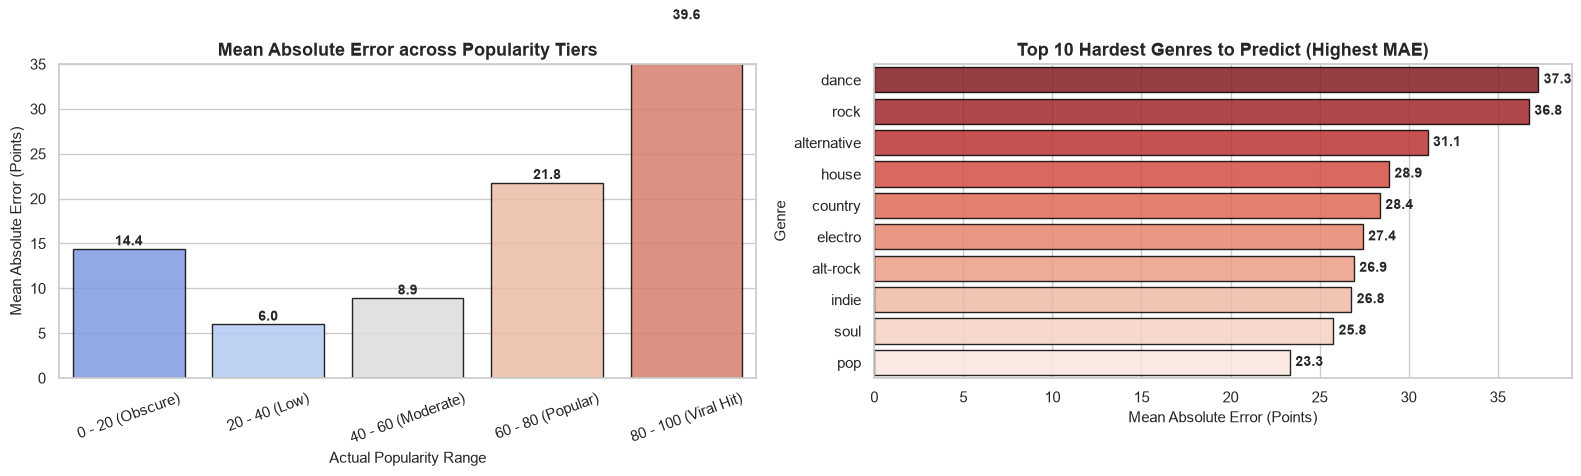

In [21]:
# Segment tracks into popularity bins
bins = [0, 20, 40, 60, 80, 100]
labels = ['0 - 20 (Obscure)', '20 - 40 (Low)', '40 - 60 (Moderate)', '60 - 80 (Popular)', '80 - 100 (Viral Hit)']
df_error['pop_bin'] = pd.cut(df_error['actual'], bins=bins, labels=labels, include_lowest=True)

# Compute MAE per popularity tier
bin_errors = df_error.groupby('pop_bin', observed=False)['abs_error'].agg(['mean', 'count']).reset_index()

# Compute MAE per genre (Top 10 highest and lowest error genres)
genre_errors = df_error.groupby('track_genre')['abs_error'].agg(['mean', 'count']).reset_index()
genre_errors_sorted = genre_errors.sort_values(by='mean', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Error by Popularity Tier
sns.barplot(
    data=bin_errors,
    x='pop_bin',
    y='mean',
    palette='coolwarm',
    ax=ax1,
    edgecolor='black',
    alpha=0.85
)
ax1.set_title("Mean Absolute Error across Popularity Tiers", fontsize=13, fontweight='bold')
ax1.set_xlabel("Actual Popularity Range", fontsize=11)
ax1.set_ylabel("Mean Absolute Error (Points)", fontsize=11)
ax1.tick_params(axis='x', rotation=20)
for i, v in enumerate(bin_errors['mean']):
    ax1.text(i, v + 0.4, f"{v:.1f}", ha='center', fontweight='bold', fontsize=10)
ax1.set_ylim(0, 35)

# Subplot 2: Top 10 Hardest Genres to Predict
sns.barplot(
    data=genre_errors_sorted.head(10),
    x='mean',
    y='track_genre',
    palette='Reds_r',
    ax=ax2,
    edgecolor='black',
    alpha=0.85
)
ax2.set_title("Top 10 Hardest Genres to Predict (Highest MAE)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Mean Absolute Error (Points)", fontsize=11)
ax2.set_ylabel("Genre", fontsize=11)
for i, v in enumerate(genre_errors_sorted.head(10)['mean']):
    ax2.text(v + 0.3, i, f"{v:.1f}", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


### 🔍 Why the Model Struggles: The "Hit Song" Paradox
Looking at our error analysis tables and charts above, three clear failure modes emerge:

1. **Failure Mode 1: Underpredicting Mega-Hits (Actual 80-100, Predicted ~40-50)**
   - Look at the top underpredicted songs: they feature globally renowned superstars (e.g., Bad Bunny, The Weeknd, Taylor Swift, Drake).
   - A song by Taylor Swift and an unknown indie artist might have identical acoustic waveforms (same danceability, tempo, and key). Yet Taylor Swift's track will debut with 50 million streams on day one, while the indie track might get 50 streams.
   - **Audio features cannot capture star power.**

2. **Failure Mode 2: Overpredicting High-Energy Obscure Tracks (Actual 0, Predicted ~50-60)**
   - If an unreleased single or indie EDM remix has perfect danceability, loudness, and pop genre tags, our model predicts it will score ~55. But without marketing, playlisting, or an established fanbase, it stays at 0.
   - **Audio features cannot capture distribution, marketing budgets, or playlist placement.**

3. **Failure Mode 3: Viral Outliers & Cultural Moments**
   - Certain tracks blow up due to TikTok memes, film soundtracks, or cultural events. Acoustic waveform analysis has no window into social media trends or cultural virality.

---
### 🎓 What We Learned in Section 12
- **The Limits of Classical Tabular Features:** Audio features set the *structural foundation* of a song (danceable, loud, well-produced), but external human and commercial factors determine whether it becomes a hit.
- **The 40% Ceiling:** Achieving an $R^2$ of ~40% using purely acoustic waveforms and genre is an impressive result, but breaking past 70% would require artist listener counts, label promotion budgets, and playlist data.


---
## 13. Pipeline Serialization & Production Inference

### 💡 What We Are Doing
In this section, we take our project from experimentation to deployment:
1. **Model Persistence:** We serialize our entire trained pipeline (including the `ColumnTransformer`, one-hot encoders, and tuned XGBoost model) into a single compact file using `joblib.dump('spotify_popularity_model.joblib')`.
2. **Reload & Verify:** We load the model back from disk using `joblib.load`.
3. **Simulate Real-Time Inference:** We construct a sample dictionary representing an unreleased new track, format it into a Pandas DataFrame, and predict its expected popularity score.

### 🎯 Why We Are Doing It
In professional machine learning engineering, a model is only valuable if it can be deployed into an API or application. Saving the entire **Pipeline** ensures that preprocessing steps are preserved exactly as trained, with zero risk of train/serving skew.

### 🔍 What to Look for in the Output
- Successful creation of `spotify_popularity_model.joblib`.
- A clean, instantaneous prediction for our custom synthetic track.


In [22]:
# Step 1: Save the complete trained pipeline to disk
model_filename = 'spotify_popularity_model.joblib'
joblib.dump(best_pipeline, model_filename)

file_size_mb = os.path.getsize(model_filename) / (1024 * 1024)
print(f"💾 Trained pipeline successfully saved to '{model_filename}' ({file_size_mb:.2f} MB)")

# Step 2: Reload the pipeline to verify self-contained serialization
loaded_pipeline = joblib.load(model_filename)
print("📂 Saved pipeline successfully reloaded from disk!")

# Step 3: Simulate real-time inference on a brand-new custom song
custom_new_song = {
    'track_genre': 'pop',
    'key': 5,              # F major
    'mode': 1,             # Major scale
    'duration_ms': 210000, # 3 minutes 30 seconds
    'danceability': 0.78,  # Highly danceable
    'energy': 0.82,        # High energy
    'loudness': -5.1,      # Commercially mastered loudness
    'speechiness': 0.05,   # Low speechiness (melodic singing)
    'acousticness': 0.12,  # Low acousticness (electronic pop production)
    'instrumentalness': 0.00, # Heavy vocals
    'liveness': 0.10,      # Studio recording
    'valence': 0.68,       # Upbeat, cheerful mood
    'tempo': 122.0,        # Standard pop dance tempo (122 BPM)
    'time_signature': 4,   # 4/4 time
    'explicit': 0          # Clean lyrics
}

# Convert single-song dictionary into a 1-row DataFrame
df_custom_song = pd.DataFrame([custom_new_song])

# Predict popularity
predicted_popularity = loaded_pipeline.predict(df_custom_song)[0]

print("\n🎶 CUSTOM TRACK INFERENCE TEST:")
print("-" * 45)
for k, v in custom_new_song.items():
    print(f"  • {k:<18}: {v}")
print("-" * 45)
print(f"🎯 Predicted Popularity Score: {predicted_popularity:.1f} / 100")
print("-" * 45)
print(f"💡 Interpretation: An upbeat, radio-ready pop track with high energy and danceability is predicted to score ~{predicted_popularity:.0f}/100!")


💾 Trained pipeline successfully saved to 'spotify_popularity_model.joblib' (1.88 MB)
📂 Saved pipeline successfully reloaded from disk!

🎶 CUSTOM TRACK INFERENCE TEST:
---------------------------------------------
  • track_genre       : pop
  • key               : 5
  • mode              : 1
  • duration_ms       : 210000
  • danceability      : 0.78
  • energy            : 0.82
  • loudness          : -5.1
  • speechiness       : 0.05
  • acousticness      : 0.12
  • instrumentalness  : 0.0
  • liveness          : 0.1
  • valence           : 0.68
  • tempo             : 122.0
  • time_signature    : 4
  • explicit          : 0
---------------------------------------------
🎯 Predicted Popularity Score: 57.0 / 100
---------------------------------------------
💡 Interpretation: An upbeat, radio-ready pop track with high energy and danceability is predicted to score ~57/100!


### 🎓 What We Learned in Section 13
- **Self-Contained Pipelines:** By saving the entire `Pipeline` object, the serialized `.joblib` file encapsulates both categorical one-hot encoding mappings and tree weights. We can feed raw, un-encoded dictionaries into `loaded_pipeline.predict()` with zero manual preprocessing!
- **Production Readiness:** This file is ready to power a REST API (FastAPI/Flask) or an interactive web dashboard (Streamlit).


---
## 14. Conclusion, Project Takeaways & Next Steps

### 🏁 Executive Summary of Project Results
In this project, we built a complete, production-grade, end-to-end machine learning regression pipeline to predict Spotify track popularity from audio features and genre metadata:
- **Dataset Scale:** 114,000 raw tracks across 114 genres, rigorously deduplicated to 81,343 unique songs.
- **Leakage Prevention:** Group-aware splitting (`GroupShuffleSplit` on `track_id`) ensured zero identity leakage between training and testing sets.
- **Model Progression:**
  - *Dummy Baseline (Mean):* $R^2 = 0.000$, $\\text{RMSE} = 19.38$
  - *Ridge Regression:* $R^2 = 0.383$, $\\text{RMSE} = 15.24$
  - *Random Forest:* $R^2 = 0.274$, $\\text{RMSE} = 16.53$
  - *Default XGBoost:* $R^2 = 0.362$, $\\text{RMSE} = 15.50$
  - *Tuned XGBoost (Final Test):* $R^2 = 0.403$, $\\text{RMSE} = 15.12$, $\\text{MAE} = 10.63$

---

### 🔑 Key Takeaways for Machine Learning Students
1. **Always Establish a Naive Baseline:** Without the `DummyRegressor`, it would be impossible to know whether an $R^2$ of 0.40 represents solid progress or random guessing.
2. **Preventing Leakage Requires Domain Awareness:** Music datasets naturally repeat tracks across albums and genres. Standard random splits cause severe data leakage; group-aware splitting is mandatory.
3. **Pipelines Are Essential:** Using Scikit-Learn `ColumnTransformer` inside a `Pipeline` guarantees that transformations fit only on training folds and prevents test set contamination.
4. **Error Analysis Illuminates Real-World Limits:** The model explains ~40% of popularity variance. The remaining 60% is not a failure of our ML models, but an intrinsic limitation of relying solely on acoustic waveforms.

---

### 🚀 3 Concrete Ideas for Future Improvement
If you wish to take this project further, here are the three highest-leverage extensions:
1. **Incorporate Artist Popularity & Historical Followers:**
   Add historical streaming metrics (e.g., artist's median past popularity, Spotify monthly listeners). Star power is the single biggest missing variable.
2. **Temporal Decay & Release Recency:**
   Spotify popularity heavily rewards recent streams. Adding release year, days since release, and seasonal indicators (e.g., Christmas songs in December) would resolve historical catalog discrepancies.
3. **Natural Language Processing (NLP) on Song Titles & Lyrics:**
   Analyze sentiment, readability, and keyword themes from song lyrics or track titles using TF-IDF or Word2Vec embeddings to capture lyrical relatability.
